In [1]:
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from numpy.lib.stride_tricks import sliding_window_view
from scipy import ndimage as ndi
from skimage import data
from skimage.metrics import peak_signal_noise_ratio as psnr, structural_similarity as ssim

plt.rcParams['figure.dpi'] = 110
plt.rcParams['image.cmap'] = 'gray'
rng = np.random.default_rng(7)

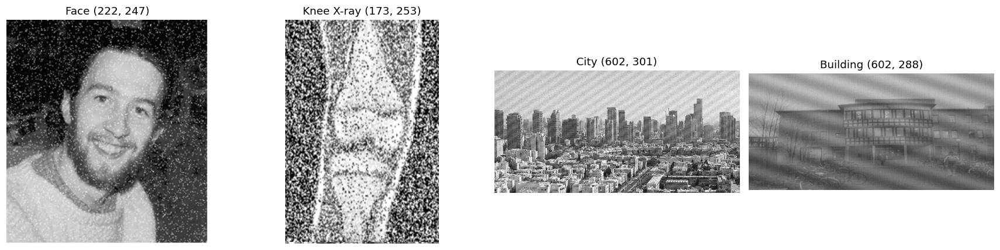

In [2]:
paths = {
    'Face': 'images/img1.png',
    'Knee X-ray': 'images/img2.png',
    'City': 'images/img3.png',
    'Building': 'images/img4.png',
}
imgs = {k: cv2.imread(v, cv2.IMREAD_GRAYSCALE) for k, v in paths.items()}

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (k, v) in zip(ax, imgs.items()):
    a.imshow(v, vmin=0, vmax=255)
    a.set_title(f'{k} {v.shape[::-1]}')
    a.axis('off')
plt.tight_layout()
plt.show()

            impulse_pixels_%  sigma_est  peak_prominence
image                                                   
Face                    8.71      12.01             2.43
Knee X-ray             10.88      19.37             1.35
City                    0.68      10.52             3.20
Building                0.00       9.66             5.44


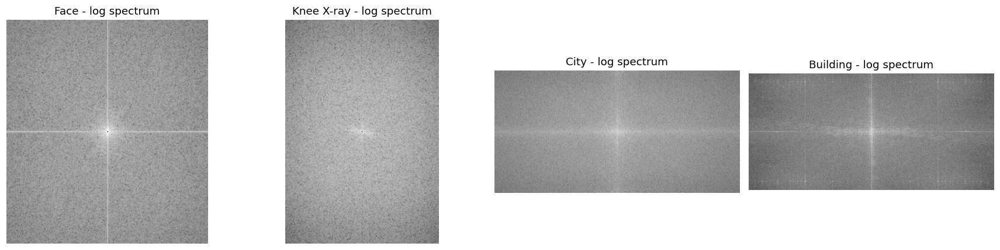

In [3]:
def estimate_sigma(im):
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    r = cv2.filter2D(im.astype(np.float64), -1, k)[1:-1, 1:-1]
    return float(np.sqrt(np.pi / 2) * np.abs(r).sum() / (6 * r.size))

def impulse_fraction(im):
    return float(np.mean((im <= 5) | (im >= 250)))

def log_spectrum(im):
    f = np.fft.fftshift(np.fft.fft2(im.astype(float) - im.mean()))
    return np.log1p(np.abs(f))

def spectral_peak_prominence(im):
    s = log_spectrum(im)
    pr = s - ndi.median_filter(s, size=9)
    h, w = s.shape
    pr[h // 2 - 1:h // 2 + 2, w // 2 - 1:w // 2 + 2] = 0
    return float(pr.max())

rows = []
for k, v in imgs.items():
    rows.append({
        'image': k,
        'impulse_pixels_%': round(100 * impulse_fraction(v), 2),
        'sigma_est': round(estimate_sigma(v), 2),
        'peak_prominence': round(spectral_peak_prominence(v), 2),
    })
noise_table = pd.DataFrame(rows).set_index('image')
print(noise_table)

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, (k, v) in zip(ax, imgs.items()):
    a.imshow(log_spectrum(v))
    a.set_title(f'{k} - log spectrum')
    a.axis('off')
plt.tight_layout()
plt.show()

In [4]:
def median_filter(im, k):
    return cv2.medianBlur(im, k)

def alpha_trimmed_mean(im, k, alpha=0.25):
    p = k // 2
    x = np.pad(im.astype(np.float32), p, mode='reflect')
    w = sliding_window_view(x, (k, k)).reshape(im.shape[0], im.shape[1], -1)
    w = np.sort(w, axis=-1)
    d = int(alpha * k * k)
    return np.clip(w[..., d:k * k - d].mean(-1), 0, 255).astype(np.uint8)

def morph_open_close(im, k):
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))
    return cv2.morphologyEx(cv2.morphologyEx(im, cv2.MORPH_OPEN, se), cv2.MORPH_CLOSE, se)

def adaptive_median(im, smax=11):
    p = smax // 2
    x = np.pad(im, p, mode='reflect')
    out = im.copy()
    for i in range(im.shape[0]):
        for j in range(im.shape[1]):
            s = 3
            while True:
                r = s // 2
                w = x[i + p - r:i + p + r + 1, j + p - r:j + p + r + 1]
                zmin, zmed, zmax = int(w.min()), int(np.median(w)), int(w.max())
                if zmin < zmed < zmax:
                    if not (zmin < im[i, j] < zmax):
                        out[i, j] = zmed
                    break
                s += 2
                if s > smax:
                    out[i, j] = zmed
                    break
    return out

def box_mean(im, k):
    return cv2.blur(im, (k, k))

def gaussian(im, k):
    return cv2.GaussianBlur(im, (k, k), 0)

def edge_strength(im):
    gx = cv2.Sobel(im.astype(np.float32), cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(im.astype(np.float32), cv2.CV_32F, 0, 1, ksize=3)
    g = np.hypot(gx, gy)
    return float(np.percentile(g, 95))

def epi(ref, test):
    a = cv2.Laplacian(ref.astype(np.float32), cv2.CV_32F)
    b = cv2.Laplacian(test.astype(np.float32), cv2.CV_32F)
    a = a - a.mean()
    b = b - b.mean()
    return float((a * b).sum() / np.sqrt((a ** 2).sum() * (b ** 2).sum()))

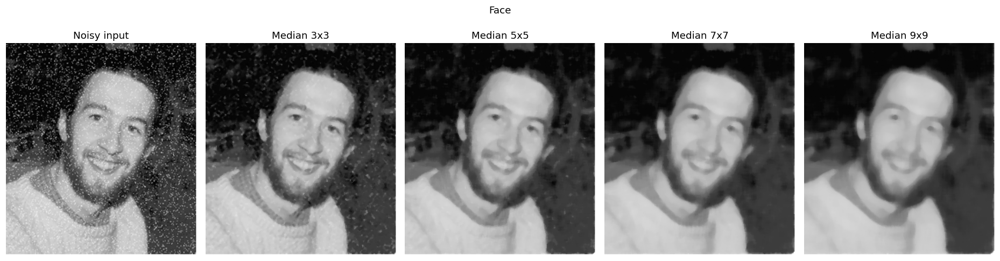

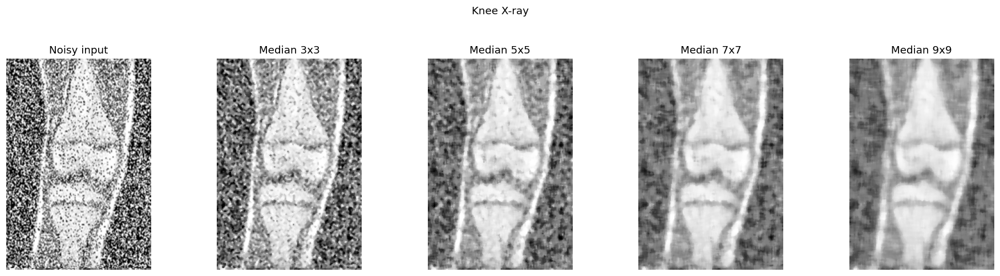

In [5]:
sizes = [3, 5, 7, 9]
for name in ['Face', 'Knee X-ray']:
    im = imgs[name]
    fig, ax = plt.subplots(1, 5, figsize=(17, 4.2))
    ax[0].imshow(im, vmin=0, vmax=255)
    ax[0].set_title('Noisy input')
    for a, k in zip(ax[1:], sizes):
        a.imshow(median_filter(im, k), vmin=0, vmax=255)
        a.set_title(f'Median {k}x{k}')
    for a in ax:
        a.axis('off')
    fig.suptitle(name, y=1.04)
    plt.tight_layout()
    plt.show()

In [6]:
real_rows = []
for name in ['Face', 'Knee X-ray']:
    im = imgs[name]
    real_rows.append({'image': name, 'filter': 'input', 'size': 0,
                      'impulse_left_%': round(100 * impulse_fraction(im), 2),
                      'sigma_est': round(estimate_sigma(im), 2),
                      'edge_p95': round(edge_strength(im), 1)})
    for k in sizes:
        out = median_filter(im, k)
        real_rows.append({'image': name, 'filter': 'median', 'size': k,
                          'impulse_left_%': round(100 * impulse_fraction(out), 2),
                          'sigma_est': round(estimate_sigma(out), 2),
                          'edge_p95': round(edge_strength(out), 1)})
real_table = pd.DataFrame(real_rows)
print(real_table.to_string(index=False))

     image filter  size  impulse_left_%  sigma_est  edge_p95
      Face  input     0            8.71      12.01     298.0
      Face median     3            3.73       2.84     178.9
      Face median     5            1.50       1.29     141.6
      Face median     7            0.96       0.87     129.5
      Face median     9            0.87       0.68     118.8
Knee X-ray  input     0           10.88      19.37     669.6
Knee X-ray median     3            3.69       9.44     438.0
Knee X-ray median     5            2.01       4.18     260.9
Knee X-ray median     7            1.13       2.45     186.4
Knee X-ray median     9            0.51       1.66     146.2


     image             filter  impulse_left_%  edge_p95
      Face              Input            8.71     298.0
      Face         Median 3x3            3.73     178.9
      Face         Median 5x5            1.50     141.6
      Face  Alpha-trimmed 5x5            2.07     122.4
      Face Morph open-close 3           11.14     156.2
      Face    Adaptive median            5.01     224.7
      Face       Box mean 5x5            0.04     120.0
Knee X-ray              Input           10.88     669.6
Knee X-ray         Median 3x3            3.69     438.0
Knee X-ray         Median 5x5            2.01     260.9
Knee X-ray  Alpha-trimmed 5x5            1.08     229.5
Knee X-ray Morph open-close 3            2.45     385.6
Knee X-ray    Adaptive median            4.78     557.3
Knee X-ray       Box mean 5x5            0.19     190.2


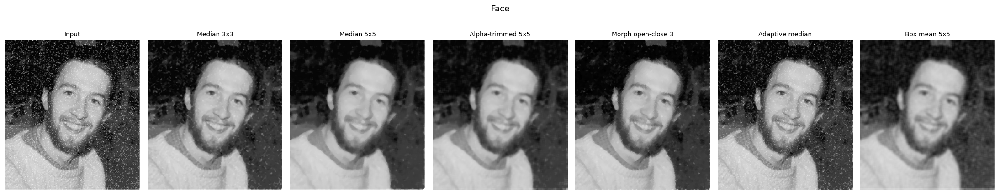

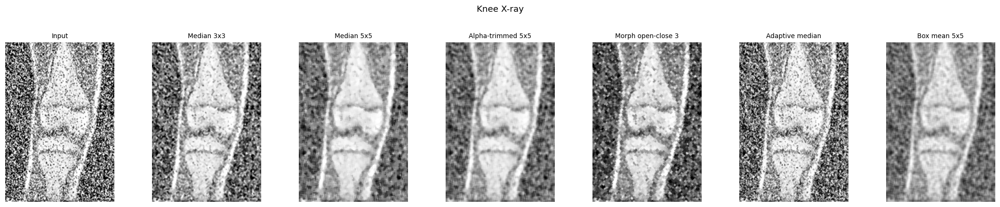

In [7]:
compare = {}
for name in ['Face', 'Knee X-ray']:
    im = imgs[name]
    compare[name] = {
        'Input': im,
        'Median 3x3': median_filter(im, 3),
        'Median 5x5': median_filter(im, 5),
        'Alpha-trimmed 5x5': alpha_trimmed_mean(im, 5, 0.25),
        'Morph open-close 3': morph_open_close(im, 3),
        'Adaptive median': adaptive_median(im, 11),
        'Box mean 5x5': box_mean(im, 5),
    }

for name, d in compare.items():
    fig, ax = plt.subplots(1, len(d), figsize=(20, 3.8))
    for a, (t, v) in zip(ax, d.items()):
        a.imshow(v, vmin=0, vmax=255)
        a.set_title(t, fontsize=9)
        a.axis('off')
    fig.suptitle(name, y=1.04)
    plt.tight_layout()
    plt.show()

rows = []
for name, d in compare.items():
    for t, v in d.items():
        rows.append({'image': name, 'filter': t,
                     'impulse_left_%': round(100 * impulse_fraction(v), 2),
                     'edge_p95': round(edge_strength(v), 1)})
print(pd.DataFrame(rows).to_string(index=False))

City spectral peaks removed: 2
Building spectral peaks removed: 50


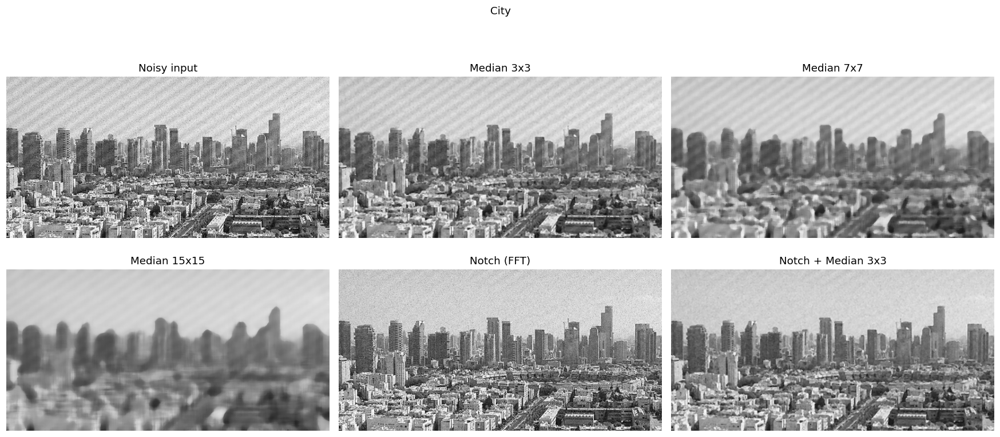

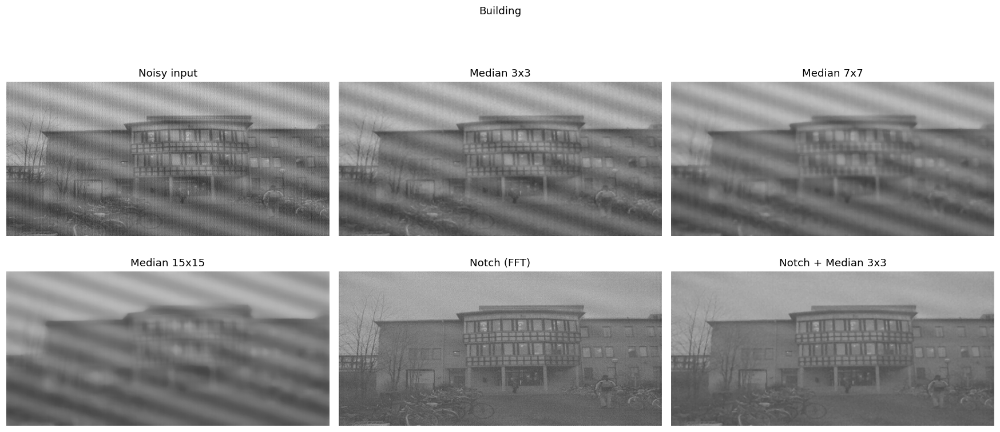

In [8]:
def notch_filter(im, thresh=3.0, radius=3, guard=1):
    f = np.fft.fftshift(np.fft.fft2(im.astype(float)))
    mag = np.log1p(np.abs(f))
    bg = ndi.median_filter(mag, size=9)
    h, w = im.shape
    cy, cx = h // 2, w // 2
    yy, xx = np.ogrid[:h, :w]
    peaks = (mag - bg) > thresh
    peaks[cy - guard:cy + guard + 1, cx - guard:cx + guard + 1] = False
    mask = np.ones((h, w), np.float32)
    for y, x in zip(*np.nonzero(peaks)):
        mask[(yy - y) ** 2 + (xx - x) ** 2 <= radius ** 2] = 0
    out = np.fft.ifft2(np.fft.ifftshift(f * mask)).real
    return np.clip(out, 0, 255).astype(np.uint8), int(peaks.sum())

periodic = {}
for name in ['City', 'Building']:
    im = imgs[name]
    nf, n_peaks = notch_filter(im)
    periodic[name] = {
        'Noisy input': im,
        'Median 3x3': median_filter(im, 3),
        'Median 7x7': median_filter(im, 7),
        'Median 15x15': median_filter(im, 15),
        'Notch (FFT)': nf,
        'Notch + Median 3x3': median_filter(nf, 3),
    }
    print(name, 'spectral peaks removed:', n_peaks)

for name, d in periodic.items():
    fig, ax = plt.subplots(2, 3, figsize=(16, 7))
    for a, (t, v) in zip(ax.ravel(), d.items()):
        a.imshow(v, vmin=0, vmax=255)
        a.set_title(t)
        a.axis('off')
    fig.suptitle(name, y=1.04)
    plt.tight_layout()
    plt.show()

   image             filter  peak_prominence  edge_p95
    City        Noisy input             3.20     454.2
    City         Median 3x3             3.12     312.3
    City         Median 7x7             2.98     160.0
    City       Median 15x15             2.67      73.3
    City        Notch (FFT)             2.04     453.6
    City Notch + Median 3x3             2.03     311.2
Building        Noisy input             5.44     117.0
Building         Median 3x3             3.75      78.6
Building         Median 7x7             4.35      44.2
Building       Median 15x15             3.82      27.5
Building        Notch (FFT)             2.91     103.2
Building Notch + Median 3x3             2.74      78.1


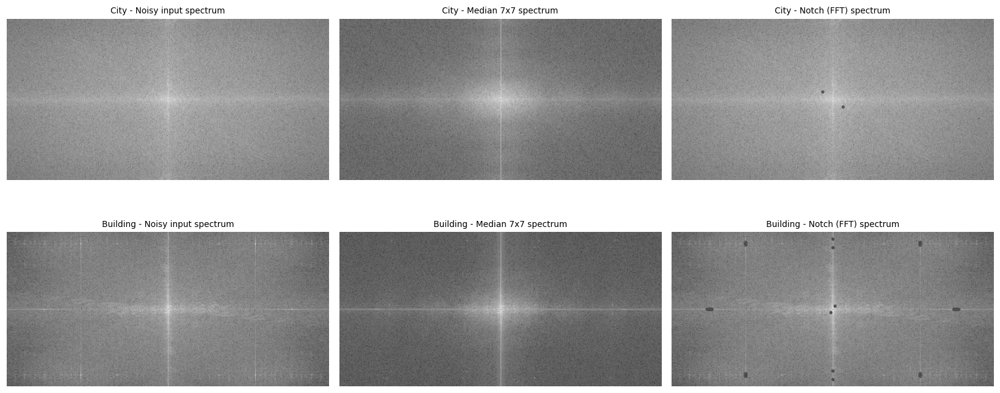

In [9]:
rows = []
for name, d in periodic.items():
    for t, v in d.items():
        rows.append({'image': name, 'filter': t,
                     'peak_prominence': round(spectral_peak_prominence(v), 2),
                     'edge_p95': round(edge_strength(v), 1)})
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots(2, 3, figsize=(15, 7))
for r, name in enumerate(['City', 'Building']):
    for c, t in enumerate(['Noisy input', 'Median 7x7', 'Notch (FFT)']):
        ax[r, c].imshow(log_spectrum(periodic[name][t]))
        ax[r, c].set_title(f'{name} - {t} spectrum', fontsize=9)
        ax[r, c].axis('off')
plt.tight_layout()
plt.show()

In [10]:
clean = cv2.resize(data.camera(), (256, 256), interpolation=cv2.INTER_AREA)

def salt_pepper(x, amount):
    u = rng.random(x.shape)
    y = x.copy()
    y[u < amount / 2] = 0.0
    y[(u >= amount / 2) & (u < amount)] = 1.0
    return y

def add_noise(kind):
    x = clean.astype(float) / 255
    if kind.startswith('Salt&pepper'):
        y = salt_pepper(x, int(kind.split()[-1].strip('%')) / 100)
    elif kind == 'Gaussian s=20':
        y = x + rng.normal(0, 20 / 255, x.shape)
    elif kind == 'Speckle':
        y = x + x * rng.normal(0, 0.2, x.shape)
    elif kind == 'Periodic':
        yy, xx = np.mgrid[:256, :256]
        y = x + 0.15 * np.sin(2 * np.pi * (xx * 0.06 + yy * 0.03))
    return (np.clip(y, 0, 1) * 255).astype(np.uint8)

noise_kinds = ['Salt&pepper 10%', 'Salt&pepper 30%', 'Salt&pepper 50%',
               'Gaussian s=20', 'Speckle', 'Periodic']
noisy = {k: add_noise(k) for k in noise_kinds}

filters = {}
for k in [3, 5, 7, 9]:
    filters[f'Median {k}'] = lambda im, k=k: median_filter(im, k)
for k in [5, 7]:
    filters[f'Alpha-trimmed {k}'] = lambda im, k=k: alpha_trimmed_mean(im, k, 0.25)
for k in [3, 5]:
    filters[f'Morph open-close {k}'] = lambda im, k=k: morph_open_close(im, k)
filters['Box mean 5'] = lambda im: box_mean(im, 5)
filters['Gaussian 5'] = lambda im: gaussian(im, 5)

rows = []
outputs = {}
for nk, ni in noisy.items():
    rows.append({'noise': nk, 'filter': 'No filter',
                 'PSNR': psnr(clean, ni), 'SSIM': ssim(clean, ni), 'EPI': epi(clean, ni)})
    for fk, fn in filters.items():
        out = fn(ni)
        outputs[(nk, fk)] = out
        rows.append({'noise': nk, 'filter': fk,
                     'PSNR': psnr(clean, out), 'SSIM': ssim(clean, out), 'EPI': epi(clean, out)})
results = pd.DataFrame(rows)
print(results.round(3).to_string(index=False))

          noise             filter   PSNR  SSIM    EPI
Salt&pepper 10%          No filter 14.918 0.213  0.160
Salt&pepper 10%           Median 3 29.131 0.868  0.485
Salt&pepper 10%           Median 5 25.560 0.783  0.301
Salt&pepper 10%           Median 7 24.076 0.732  0.223
Salt&pepper 10%           Median 9 23.366 0.705  0.221
Salt&pepper 10%    Alpha-trimmed 5 25.643 0.781  0.147
Salt&pepper 10%    Alpha-trimmed 7 24.070 0.726 -0.003
Salt&pepper 10% Morph open-close 3 25.662 0.834  0.350
Salt&pepper 10% Morph open-close 5 19.695 0.692  0.134
Salt&pepper 10%         Box mean 5 22.760 0.494 -0.004
Salt&pepper 10%         Gaussian 5 23.160 0.465  0.275
Salt&pepper 30%          No filter 10.017 0.079  0.071
Salt&pepper 30%           Median 3 22.064 0.690  0.145
Salt&pepper 30%           Median 5 24.767 0.768  0.167
Salt&pepper 30%           Median 7 23.763 0.725  0.134
Salt&pepper 30%           Median 9 23.199 0.700  0.138
Salt&pepper 30%    Alpha-trimmed 5 23.743 0.613  0.036
Salt&peppe

                             filter    PSNR   SSIM    EPI
noise                                                    
Salt&pepper 10%            Median 3  29.131  0.868  0.485
Salt&pepper 30%            Median 5  24.767  0.768  0.167
Salt&pepper 50%            Median 7  22.877  0.702  0.044
Gaussian s=20            Gaussian 5  26.897  0.711  0.456
Speckle                  Gaussian 5  25.826  0.654  0.388
Periodic         Morph open-close 5  20.225  0.346  0.414


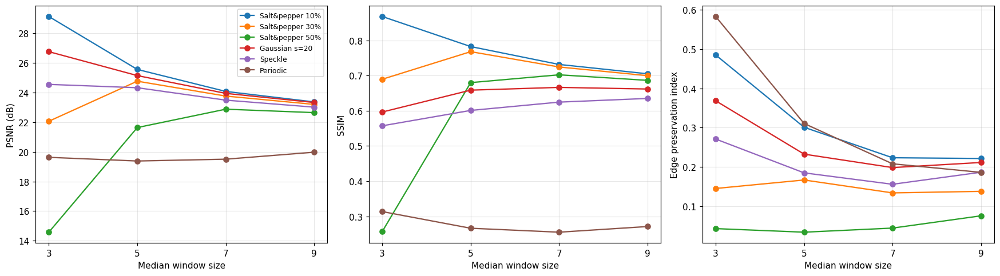

In [11]:
best = results[results['filter'] != 'No filter'].sort_values('PSNR', ascending=False).groupby('noise').head(1)
best = best.set_index('noise').loc[noise_kinds]
print(best.round(3))

med = results[results['filter'].str.startswith('Median')].copy()
med['size'] = med['filter'].str.extract(r'(\d+)').astype(int)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for nk in noise_kinds:
    d = med[med['noise'] == nk].sort_values('size')
    ax[0].plot(d['size'], d['PSNR'], marker='o', label=nk)
    ax[1].plot(d['size'], d['SSIM'], marker='o', label=nk)
    ax[2].plot(d['size'], d['EPI'], marker='o', label=nk)
for a, t in zip(ax, ['PSNR (dB)', 'SSIM', 'Edge preservation index']):
    a.set_xlabel('Median window size')
    a.set_ylabel(t)
    a.set_xticks([3, 5, 7, 9])
    a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

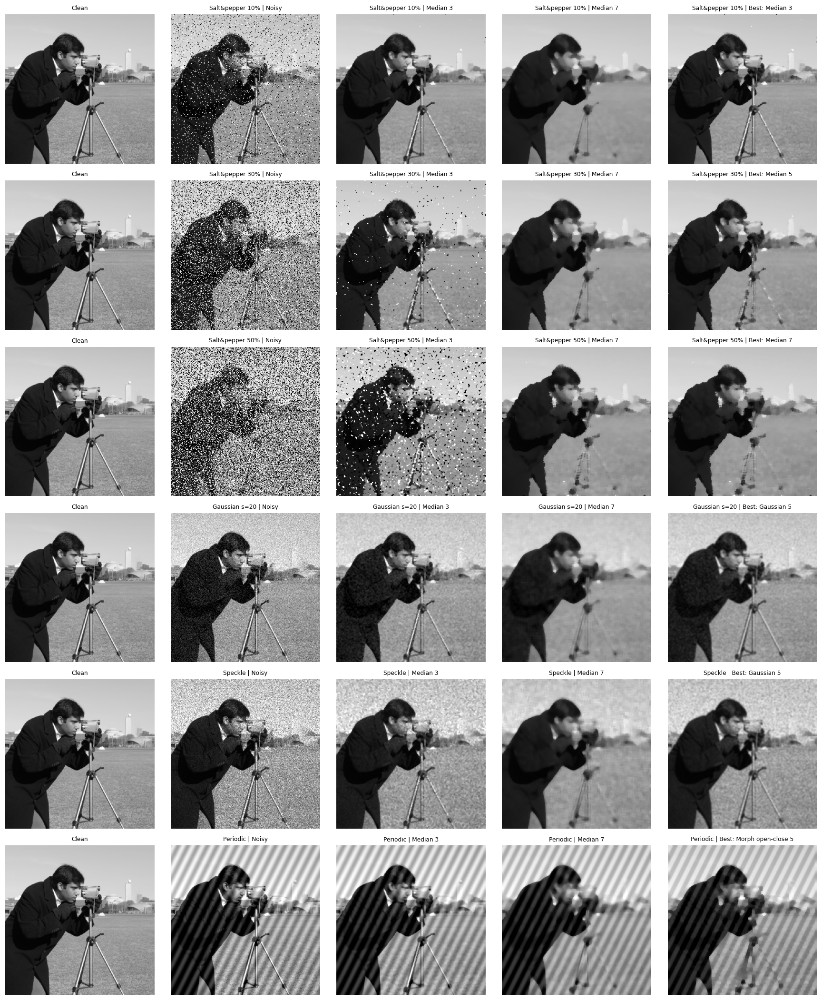

In [12]:
fig, ax = plt.subplots(len(noise_kinds), 5, figsize=(16, 3.2 * len(noise_kinds)))
for r, nk in enumerate(noise_kinds):
    bf = best.loc[nk, 'filter']
    panels = [('Clean', clean), ('Noisy', noisy[nk]),
              ('Median 3', outputs[(nk, 'Median 3')]),
              ('Median 7', outputs[(nk, 'Median 7')]),
              (f'Best: {bf}', outputs[(nk, bf)])]
    for c, (t, v) in enumerate(panels):
        ax[r, c].imshow(v, vmin=0, vmax=255)
        ax[r, c].set_title(f'{nk} | {t}' if c else t, fontsize=8)
        ax[r, c].axis('off')
plt.tight_layout()
plt.show()

   structure  window  PSNR  SSIM
Fine stripes       3 15.04 0.081
Fine stripes       7 15.01 0.037
  Thin lines       3 18.90 0.816
  Thin lines       7 18.78 0.811
  Small dots       3 24.15 0.951
  Small dots       7 18.96 0.883


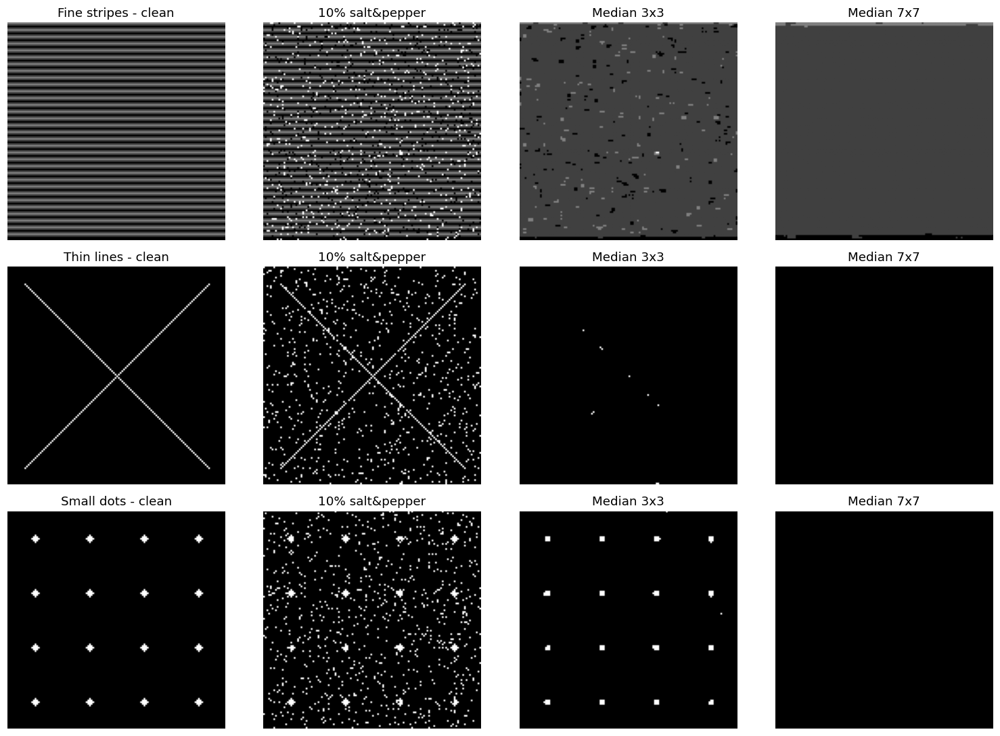

In [13]:
im = clean
fine = np.zeros((128, 128), np.uint8)
fine[::4, :] = 255
fine = cv2.GaussianBlur(fine, (3, 3), 0)
thin = np.zeros((128, 128), np.uint8)
cv2.line(thin, (10, 10), (118, 118), 255, 1)
cv2.line(thin, (10, 118), (118, 10), 255, 1)
dots = np.zeros((128, 128), np.uint8)
for y in range(16, 128, 32):
    for x in range(16, 128, 32):
        cv2.circle(dots, (x, y), 2, 255, -1)

tests = {'Fine stripes': fine, 'Thin lines': thin, 'Small dots': dots}
rows = []
fig, ax = plt.subplots(3, 4, figsize=(14, 10))
for r, (t, ref) in enumerate(tests.items()):
    ni = (salt_pepper(ref / 255.0, 0.10) * 255).astype(np.uint8)
    ax[r, 0].imshow(ref, vmin=0, vmax=255); ax[r, 0].set_title(f'{t} - clean')
    ax[r, 1].imshow(ni, vmin=0, vmax=255); ax[r, 1].set_title('10% salt&pepper')
    for c, k in enumerate([3, 7]):
        out = median_filter(ni, k)
        ax[r, 2 + c].imshow(out, vmin=0, vmax=255)
        ax[r, 2 + c].set_title(f'Median {k}x{k}')
        rows.append({'structure': t, 'window': k, 'PSNR': round(psnr(ref, out), 2),
                     'SSIM': round(ssim(ref, out), 3)})
    for a in ax[r]:
        a.axis('off')
plt.tight_layout()
plt.show()
print(pd.DataFrame(rows).to_string(index=False))

In [14]:
summary = best[['filter', 'PSNR', 'SSIM', 'EPI']].copy()
base = results[results['filter'] == 'No filter'].set_index('noise').loc[noise_kinds]
summary['PSNR_gain_dB'] = summary['PSNR'] - base['PSNR']
print(summary.round(3))

med_only = med.sort_values('PSNR', ascending=False).groupby('noise').head(1).set_index('noise').loc[noise_kinds]
print(med_only[['filter', 'PSNR', 'SSIM', 'EPI']].round(3))

                             filter    PSNR   SSIM    EPI  PSNR_gain_dB
noise                                                                  
Salt&pepper 10%            Median 3  29.131  0.868  0.485        14.214
Salt&pepper 30%            Median 5  24.767  0.768  0.167        14.750
Salt&pepper 50%            Median 7  22.877  0.702  0.044        15.063
Gaussian s=20            Gaussian 5  26.897  0.711  0.456         4.482
Speckle                  Gaussian 5  25.826  0.654  0.388         6.620
Periodic         Morph open-close 5  20.225  0.346  0.414         0.445
                   filter    PSNR   SSIM    EPI
noise                                          
Salt&pepper 10%  Median 3  29.131  0.868  0.485
Salt&pepper 30%  Median 5  24.767  0.768  0.167
Salt&pepper 50%  Median 7  22.877  0.702  0.044
Gaussian s=20    Median 3  26.758  0.597  0.369
Speckle          Median 3  24.551  0.557  0.271
Periodic         Median 9  19.975  0.271  0.186
